# AirLab - 16S · бактерии · SILVA 144 - полный анализ с исходных FASTQ

FASTQ → FastQC/MultiQC → проверка праймеров → Cutadapt → фильтрация DADA2 → обучение ошибок → денойзинг → объединение → ASV → химеры → таксономия → `phyloseq` → альфа-/бета-разнообразие → предварительные связи с погодой.

- Вход: только **исходные FASTQ**, **референсная FASTA** и опубликованные метаданные (их базовая копия встроена в ноутбук; внешний `metadata/samples_pnas.tsv` используется лишь как обновляемый источник метаданных, если он присутствует).
- Результаты будут записаны в `~/airlab/pipeline/results/16S/`. Исходные FASTQ не изменяются.
- Запускай ячейки **сверху вниз** (`Shift+Enter`), в R-ядре окружения `~/airlab/envs/amplicon` на выделенном через SLURM вычислительном узле. На `sms` расчёты не запускать.

**16S:** после удаления праймеров выполняется DADA2 с `truncLen = c(0,0)` как начальный режим. Видовые совпадения определяются по отдельному файлу SILVA `addSpecies()` (точное совпадение участка 16S не гарантирует идентификации вида). После таксономии исключаются ASV, помеченные как хлоропласты или митохондрии. Предварительная таблица сохраняется до исключения.

**Статус исследования:** без отрицательных контролей нельзя считать выполненной проверку загрязнений (`decontam`), а без реальных измерений погоды — анализ экстремальных явлений. Статистика по Flight/Ground предварительная, не причинная. Это адаптированный анализ, не идентичное воспроизведение опубликованной версии QIIME2/референсов.

Официальные инструкции: [DADA2](https://benjjneb.github.io/dada2/tutorial.html), [DADA2 ITS](https://benjjneb.github.io/dada2/ITS_workflow.html), [референсы](https://benjjneb.github.io/dada2/training.html), [Cutadapt](https://cutadapt.readthedocs.io/en/stable/guide.html).

## 0. Установленные зависимости и запуск на кластере

**Используем существующее окружение:** `/home/panishevasa/airlab/envs/amplicon` (R 4.5.3, DADA2, phyloseq, ShortRead, Biostrings, vegan, ggplot2, IRkernel, FastQC, MultiQC, Cutadapt). 

Если окружение когда-нибудь придётся **создать заново**, это делается **на `sms`** (вычислительные узлы могут не иметь доступа в интернет), а не внутри R:

```bash
~/tools/bin/micromamba create -y -p ~/airlab/envs/amplicon -c conda-forge -c bioconda \
  r-base=4.5 bioconductor-dada2 bioconductor-phyloseq \
  bioconductor-shortread bioconductor-biostrings r-vegan r-ggplot2 \
  fastqc multiqc cutadapt jupyterlab r-irkernel
```

JupyterLab запускается после `srun -p normal -c 2 -t 03:00:00 --pty bash` , на назначенном узле. Для Windows нужен SSH-туннель вида `ssh -N -L 8888:cn-XXX:8888 panishevasa@АДРЕС_СЕРВЕРА`. `cn-XXX` — реально выделенный узел.

**Ресурсы:** для DADA2 может потребоваться более длительное SLURM-задание. Сохранённый `.rds` не заменяет повторного выполнения ячеек, но позволяет анализировать результаты в отдельной будущей сессии.

## 1. Настройки и функции

Все параметры заданы **в этом ноутбуке**: внешний `config.yaml` **не требуется**. Если меняешь параметры, перезапусти анализ **с первой ячейки** и не смешивай результаты двух настроек. Параллельность ограничена количеством ядер, выделенных SLURM.

In [1]:
project_dir <- "/home/panishevasa/airlab/pipeline"
raw_dir <- "/home/panishevasa/airlab/test_16S_ITS_data"
env_bin <- "/home/panishevasa/airlab/envs/amplicon/bin"
marker <- "16S"
primer_fwd <- "CCTACGGGNGGCWGCAG"
primer_rev <- "GACTACHVGGGTATCTAATCC"
taxonomy_ref <- file.path(project_dir, "refdb/silva_v144/silva_nr99_v144_toGenus_trainset.fa.gz")
species_ref <- file.path(project_dir, "refdb/silva_v144/silva_v144_assignSpecies.fa.gz")
tax_levels <- c("Domain", "Kingdom", "Phylum", "Class", "Order", "Family", "Genus")
try_rc <- FALSE
fungi_only <- FALSE

run_fastqc <- TRUE
max_ee <- c(2, 2)
trunc_len <- c(0L, 0L)
min_len <- 50L
min_reads <- 100L
min_boot <- 80L
pooling <- "pseudo"
min_overlap <- 12L
min_pilot_retention <- 0.50  # защита от ошибочных праймеров
set.seed(139)

if (!dir.exists(project_dir)) stop("Missing project directory: ", project_dir)
if (!dir.exists(raw_dir)) stop("Missing raw FASTQ directory: ", raw_dir)
if (grepl("^sms", Sys.info()[["nodename"]])) stop("Compute on a SLURM compute node, not sms")

Sys.setenv(PATH=paste(env_bin, Sys.getenv("PATH"), sep=":"))
needed <- c("dada2", "ShortRead", "Biostrings", "phyloseq", "vegan", "ggplot2")
missing <- needed[!vapply(needed, requireNamespace, logical(1), quietly=TRUE)]
if (length(missing)) stop("Missing R packages: ", paste(missing, collapse=", "))
cli <- c("cutadapt", if (run_fastqc) c("fastqc", "multiqc"))
if (any(!nzchar(Sys.which(cli)))) stop("Missing commands: ", paste(cli[!nzchar(Sys.which(cli))], collapse=", "))
if (!file.exists(taxonomy_ref)) stop("Missing reference FASTA: ", taxonomy_ref)
if (!is.null(species_ref) && !file.exists(species_ref)) stop("Missing SILVA species FASTA: ", species_ref)

allocated <- suppressWarnings(as.integer(Sys.getenv("SLURM_CPUS_PER_TASK", "1")))
if (!is.finite(allocated) || allocated < 1L) allocated <- 1L
threads <- min(4L, allocated)
outdir <- file.path(project_dir, "results", marker)
dir.create(outdir, recursive=TRUE, showWarnings=FALSE)

run_cmd <- function(exe, arguments, log_file) {
  dir.create(dirname(log_file), recursive=TRUE, showWarnings=FALSE)
  rc <- suppressWarnings(system2(Sys.which(exe), args=shQuote(as.character(arguments)),
                                 stdout=log_file, stderr=log_file))
  if (!identical(as.integer(rc), 0L)) {
    if (file.exists(log_file)) cat(tail(readLines(log_file, warn=FALSE), 25), sep="\n")
    stop(exe, " returned exit status ", rc, "; log: ", log_file)
  }
  invisible(rc)
}
write_matrix <- function(x, filename) {
  write.table(x, file.path(outdir, filename), sep="\t", quote=FALSE,
              col.names=NA, na="NA")
}
write_rows <- function(x, filename) {
  write.table(x, file.path(outdir, filename), sep="\t", quote=FALSE,
              row.names=FALSE, na="NA")
}
get_cutadapt_n <- function(log_lines, phrase) {
  hit <- grep(phrase, log_lines, value=TRUE, fixed=TRUE)
  if (!length(hit)) return(NA_real_)
  as.numeric(gsub(",", "", sub(".*:[[:space:]]*([0-9,]+).*", "\\1", hit[1])))
}

cat("Marker:", marker, "| threads:", threads,
    "| results:", outdir, "\nReference:", taxonomy_ref, "\n")

Marker: 16S | threads: 2 | results: /home/panishevasa/airlab/pipeline/results/16S 
Reference: /home/panishevasa/airlab/pipeline/refdb/silva_v144/silva_nr99_v144_toGenus_trainset.fa.gz 


## 2. Поиск исходных FASTQ и метаданные PNAS

Строгая проверка имён пар R1/R2: нельзя объединять несовпадающие образцы. Если файла нет/он пуст, прекращаем запуск. Базовые метаданные PNAS 2024 (Supplementary Table 1) **встроены** в этот ноутбук; если существует `metadata/samples_pnas.tsv`, используем его вместо встроенной таблицы. Это входные метаданные, а не рассчитанные результаты.

In [2]:
all_files <- list.files(raw_dir, full.names=TRUE)
suffix_f <- paste0("_1_", marker, ".fastq.gz")
suffix_r <- paste0("_2_", marker, ".fastq.gz")
fn_f <- all_files[endsWith(basename(all_files), suffix_f)]
fn_r <- all_files[endsWith(basename(all_files), suffix_r)]
ids_f <- substr(basename(fn_f), 1L, nchar(basename(fn_f)) - nchar(suffix_f))
ids_r <- substr(basename(fn_r), 1L, nchar(basename(fn_r)) - nchar(suffix_r))
if (!length(ids_f) || anyDuplicated(ids_f) || anyDuplicated(ids_r) || !setequal(ids_f, ids_r)) {
  cat("Missing R2 for:", paste(setdiff(ids_f, ids_r), collapse=", "), "\n")
  cat("Missing R1 for:", paste(setdiff(ids_r, ids_f), collapse=", "), "\n")
  stop("Incomplete or duplicated R1/R2 pairs")
}
order_f <- order(ids_f)
fn_f <- fn_f[order_f]; sample_ids <- ids_f[order_f]
fn_r <- fn_r[match(sample_ids, ids_r)]
names(fn_f) <- names(fn_r) <- sample_ids
if (!all(file.info(c(fn_f, fn_r))$size > 0)) stop("Empty FASTQ files detected")
cat("Complete FASTQ pairs:", length(sample_ids), "\n")

metadata_embedded <- "sample_id\tis_control\tsite_id\tsite_type\tsampling_date\tdatetime_start\tdatetime_end\tsampling_timezone\taltitude_min_m\taltitude_max_m\tair_volume_m3\tdna_yield_ng_m3\tpublished_16S_success\tpublished_ITS_success\textraction_batch\tlibrary_batch\tseason\ttemp_c\trh_pct\twind_ms\tprecip_mm\tpressure_hpa\tpm25\tpm10\tmetadata_source\nS1\tFALSE\tNA\tFlight\t2014-02-22\t2014-02-22T12:10:00\t2014-02-22T15:00:00\tAsia/Tokyo\t1000\t3000\t83.6\t0.155\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS2\tFALSE\tNA\tGround\t2014-02-23\t2014-02-23T00:00:00\t2014-02-23T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.134\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS3\tFALSE\tNA\tFlight\t2014-02-23\t2014-02-23T12:04:00\t2014-02-23T14:50:00\tAsia/Tokyo\t1000\t3000\t83.7\t0.140\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS4\tFALSE\tNA\tGround\t2014-02-24\t2014-02-24T00:00:00\t2014-02-24T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.078\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS5\tFALSE\tNA\tFlight\t2014-02-24\t2014-02-24T12:04:00\t2014-02-24T14:38:00\tAsia/Tokyo\t1000\t3000\t84.0\t0.240\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS6\tFALSE\tNA\tGround\t2014-02-25\t2014-02-25T00:00:00\t2014-02-25T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.354\tYES\tNO\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS7\tFALSE\tNA\tFlight\t2014-02-25\t2014-02-25T12:18:00\t2014-02-25T15:00:00\tAsia/Tokyo\t1000\t3000\t88.4\t0.041\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS8\tFALSE\tNA\tGround\t2014-02-26\t2014-02-26T00:00:00\t2014-02-26T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.087\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS9\tFALSE\tNA\tFlight\t2014-02-26\t2014-02-26T12:24:00\t2014-02-26T15:10:00\tAsia/Tokyo\t1000\t3000\t82.6\t0.051\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS10\tFALSE\tNA\tGround\t2014-02-27\t2014-02-27T00:00:00\t2014-02-27T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.089\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS11\tFALSE\tNA\tGround\t2014-02-28\t2014-02-28T12:00:00\t2014-02-28T15:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.095\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS12\tFALSE\tNA\tGround\t2014-03-01\t2014-03-01T00:00:00\t2014-03-01T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.162\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS13\tFALSE\tNA\tFlight\t2014-04-01\t2014-04-01T12:10:00\t2014-04-01T14:58:00\tAsia/Tokyo\t1000\t3000\t81.3\t0.053\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS14\tFALSE\tNA\tGround\t2014-04-01\t2014-04-01T00:00:00\t2014-04-01T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.000\tNO\tNO\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS15\tFALSE\tNA\tFlight\t2014-04-05\t2014-04-05T11:50:00\t2014-04-05T14:35:00\tAsia/Tokyo\t1000\t3000\t83.9\t0.035\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS16\tFALSE\tNA\tGround\t2014-04-06\t2014-04-06T00:00:00\t2014-04-06T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.066\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS17\tFALSE\tNA\tFlight\t2014-04-06\t2014-04-06T10:47:00\t2014-04-06T13:11:00\tAsia/Tokyo\t1000\t3000\t72.9\t0.072\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS18\tFALSE\tNA\tGround\t2014-04-07\t2014-04-07T00:00:00\t2014-04-07T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.004\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS19\tFALSE\tNA\tFlight\t2014-04-07\t2014-04-07T12:15:00\t2014-04-07T14:55:00\tAsia/Tokyo\t1000\t3000\t79.7\t0.047\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS20\tFALSE\tNA\tGround\t2014-04-08\t2014-04-08T00:00:00\t2014-04-08T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.031\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS21\tFALSE\tNA\tFlight\t2014-04-08\t2014-04-08T12:15:00\t2014-04-08T14:53:00\tAsia/Tokyo\t1000\t3000\t79.0\t0.063\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1\nS22\tFALSE\tNA\tGround\t2014-04-09\t2014-04-09T00:00:00\t2014-04-09T03:00:00\tAsia/Tokyo\t42\t42\t90.0\t0.019\tYES\tYES\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tNA\tRodó_et_al_PNAS_2024_SI_Table_1_p1"
metadata_path <- file.path(project_dir, "metadata", "samples_pnas.tsv")
if (file.exists(metadata_path)) {
  published <- read.delim(metadata_path, sep="\t", na.strings="NA",
                          stringsAsFactors=FALSE, check.names=FALSE,
                          fileEncoding="UTF-8")
  cat("Metadata source:", metadata_path, "\n")
} else {
  published <- read.delim(text=metadata_embedded, sep="\t", na.strings="NA",
                          stringsAsFactors=FALSE, check.names=FALSE)
  cat("Metadata source: embedded PNAS supplementary table\n")
}
if (!"sample_id" %in% names(published) || anyDuplicated(published$sample_id))
  stop("Invalid sample_id in metadata")
if (!all(sample_ids %in% published$sample_id))
  stop("Metadata missing FASTQ IDs: ", paste(setdiff(sample_ids, published$sample_id), collapse=", "))
meta <- published[match(sample_ids, published$sample_id), , drop=FALSE]
rownames(meta) <- sample_ids
stopifnot(identical(meta$sample_id, sample_ids))
write_rows(meta, "sample_metadata_matched.tsv")

con <- if (grepl("\\.gz$", taxonomy_ref)) gzfile(taxonomy_ref, "rt") else file(taxonomy_ref, "rt")
ref_header <- readLines(con, n=1L, warn=FALSE); close(con)
if (!length(ref_header) || !startsWith(ref_header, ">")) stop("Reference file does not start with a FASTA header")
cat("Reference header:", substr(ref_header, 1, 180), "\n")
cat("Published records:", nrow(published), "| matched:", nrow(meta), "\n")
print(meta[, intersect(c("sample_id", "site_type", "sampling_date", "air_volume_m3",
                        "published_16S_success", "published_ITS_success"), names(meta)), drop=FALSE])

Complete FASTQ pairs: 21 
Metadata source: /home/panishevasa/airlab/pipeline/metadata/samples_pnas.tsv 
Reference header: >Bacteria;Pseudomonadati;Pseudomonadota;Gammaproteobacteria;Pseudomonadales;Pseudomonadaceae;Pseudomonas; 
Published records: 22 | matched: 21 
    sample_id site_type sampling_date air_volume_m3 published_16S_success
S1         S1    Flight    2014-02-22          83.6                   YES
S10       S10    Ground    2014-02-27          90.0                   YES
S11       S11    Ground    2014-02-28          90.0                   YES
S12       S12    Ground    2014-03-01          90.0                   YES
S13       S13    Flight    2014-04-01          81.3                   YES
S15       S15    Flight    2014-04-05          83.9                   YES
S16       S16    Ground    2014-04-06          90.0                   YES
S17       S17    Flight    2014-04-06          72.9                   YES
S18       S18    Ground    2014-04-07          90.0                 

## 3. Исходный контроль качества: FastQC + MultiQC

Обрабатываются **все исходные файлы** этого маркера, в том числе повторно при новом запуске. Ошибка FastQC о неполном FASTQ требует восстановления оригинального архива. Графики для первых двух образцов служат предварительной визуальной проверкой.

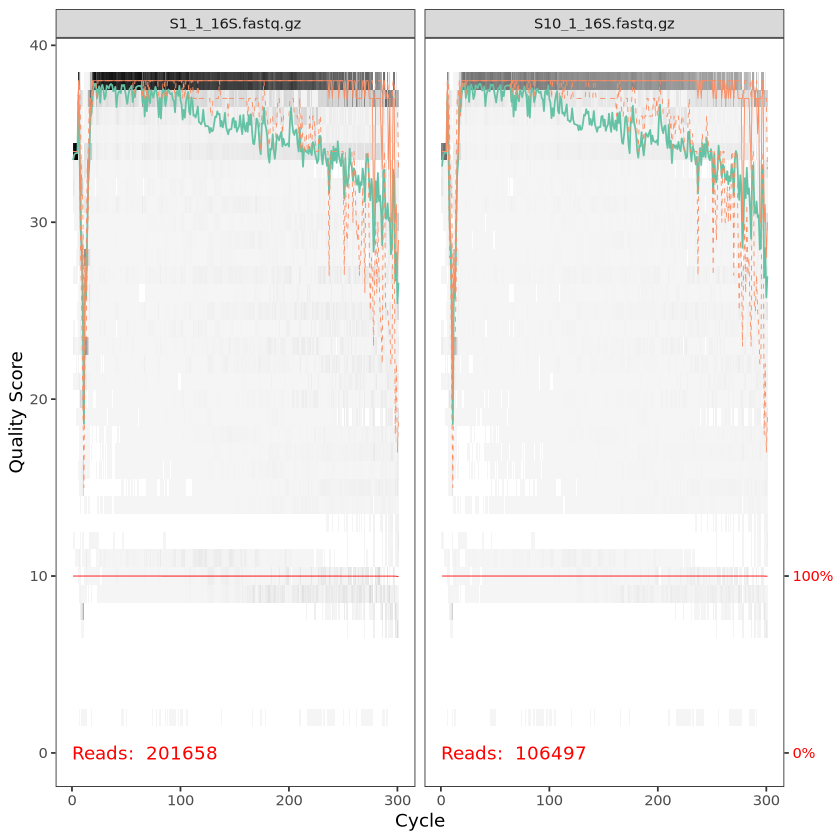

MultiQC: /home/panishevasa/airlab/pipeline/results/16S/multiqc/multiqc_report.html 


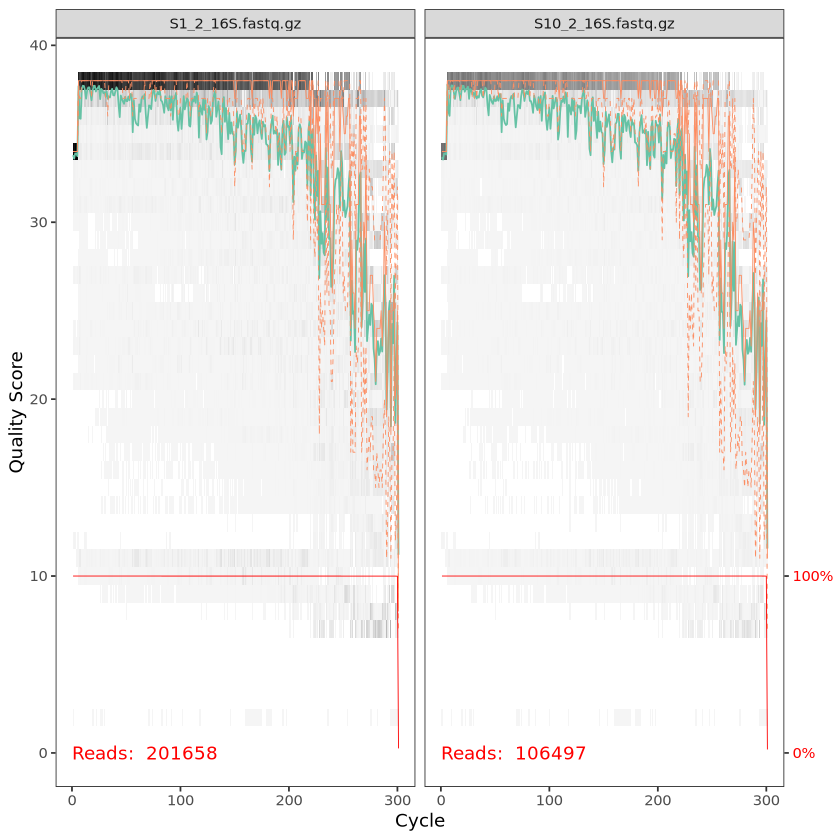

In [3]:
preview_ids <- head(sample_ids, 2L)
print(dada2::plotQualityProfile(unname(fn_f[preview_ids])))
print(dada2::plotQualityProfile(unname(fn_r[preview_ids])))
if (run_fastqc) {
  qcdir <- file.path(outdir, "fastqc")
  mqdir <- file.path(outdir, "multiqc")
  dir.create(qcdir, recursive=TRUE, showWarnings=FALSE)
  dir.create(mqdir, recursive=TRUE, showWarnings=FALSE)
  run_cmd("fastqc", c("-t", threads, "--outdir", qcdir, unname(fn_f), unname(fn_r)),
          file.path(outdir, "fastqc.log"))
  run_cmd("multiqc", c("--force", "--outdir", mqdir, qcdir),
          file.path(outdir, "multiqc.log"))
  cat("MultiQC:", file.path(mqdir, "multiqc_report.html"), "\n")
}

## 4. Ориентация праймеров (первая 500 прочтений на файл)

Проверяем строгие совпадения праймеров с началом R1/R2 с учётом IUPAC. Превышение `swapped_hits` — повод исправить источники R1/R2 вручную, а не автоматически переставлять файлы.

In [4]:
primer_hits <- function(path, primer, n=500L) {
  stream <- ShortRead::FastqStreamer(path, n=n)
  on.exit(close(stream))
  fq <- ShortRead::yield(stream)
  if (!length(fq)) return(0L)
  s <- ShortRead::sread(fq)
  s <- s[Biostrings::width(s) >= nchar(primer)]
  if (!length(s)) return(0L)
  st <- Biostrings::subseq(s, start=1L, width=nchar(primer))
  sum(Biostrings::vcountPattern(primer, st, fixed=FALSE) > 0)
}
orientation <- data.frame(sample_id=sample_ids,
  expected_hits=vapply(seq_along(sample_ids), function(i)
    primer_hits(fn_f[i], primer_fwd) + primer_hits(fn_r[i], primer_rev), numeric(1)),
  swapped_hits=vapply(seq_along(sample_ids), function(i)
    primer_hits(fn_f[i], primer_rev) + primer_hits(fn_r[i], primer_fwd), numeric(1)))
write_rows(orientation, "primer_orientation.tsv")
print(orientation, row.names=FALSE)
if (any(orientation$swapped_hits >= 10 & orientation$swapped_hits > orientation$expected_hits))
  stop("Possible R1/R2 swap: inspect primer_orientation.tsv before Cutadapt")

 sample_id expected_hits swapped_hits
        S1           948            0
       S10           956            0
       S11           953            0
       S12           949            0
       S13           935            0
       S15           945            0
       S16           948            0
       S17           932            0
       S18           928            0
       S19           933            0
        S2           944            0
       S20           926            0
       S21           910            0
       S22           932            0
        S3           965            0
        S4           940            0
        S5           938            0
        S6           955            0
        S7           950            0
        S8           948            0
        S9           967            0


## 5. Cutadapt: удаление праймеров для всех образцов

Используются **связанные адаптеры** (`-a ^5′-праймер...реверс-комплемент 3′-праймера` для R1 и `-A` для R2) в парном режиме. Обязателен 5′-праймер, а возможное 3′-продолжение удаляется для коротких ампликонов. `--pair-filter=any --discard-untrimmed` удаляет всю пару, если один из двух обязательных праймеров не найден. В первой пробе проверяется процент сохранённых пар, затем анализируются все остальные образцы. Входные FASTQ не переписываются.

Важна именно комбинация **`-a`/`-A`**: в Cutadapt 5.2 связанные адаптеры с `-g`/`-G` требовали бы одновременно 5′ и 3′ части, что отбрасывало бы многие длинные ампликоны. Это также устраняет проблему исходного варианта с раздельными адаптерами: теперь случайное совпадение только с 3′-частью не считается успешным удалением праймера.

In [5]:
trimdir <- file.path(outdir, "trimmed")
logdir <- file.path(outdir, "logs")
dir.create(trimdir, recursive=TRUE, showWarnings=FALSE)
dir.create(logdir, recursive=TRUE, showWarnings=FALSE)
trim_f <- setNames(file.path(trimdir, paste0(sample_ids, "_R1.fastq.gz")), sample_ids)
trim_r <- setNames(file.path(trimdir, paste0(sample_ids, "_R2.fastq.gz")), sample_ids)
rc_primer <- function(s) as.character(Biostrings::reverseComplement(Biostrings::DNAString(s)))
linked_f <- paste0("^", primer_fwd, "...", rc_primer(primer_rev))
linked_r <- paste0("^", primer_rev, "...", rc_primer(primer_fwd))
cut_args <- function(i) c("-a", linked_f, "-A", linked_r,
                           "--discard-untrimmed", "--pair-filter=any",
                           "--minimum-length", min_len, "-j", threads,
                           "-o", trim_f[i], "-p", trim_r[i], fn_f[i], fn_r[i])
cut_log <- function(id) file.path(logdir, paste0(id, ".cutadapt.log"))

cat("Pilot Cutadapt sample:", sample_ids[1], "\n")
run_cmd("cutadapt", cut_args(1), cut_log(sample_ids[1]))
pilot_text <- readLines(cut_log(sample_ids[1]), warn=FALSE)
cat(grep("Total read pairs processed|Read 1 with adapter|Read 2 with adapter|Pairs written|Pairs discarded",
         pilot_text, value=TRUE), sep="\n")
pilot_in <- get_cutadapt_n(pilot_text, "Total read pairs processed:")
pilot_out <- get_cutadapt_n(pilot_text, "Pairs written (passing filters):")
if (!is.finite(pilot_in) || !is.finite(pilot_out) || pilot_in == 0 ||
    pilot_out / pilot_in < min_pilot_retention)
  stop("Cutadapt pilot retained too few reads: inspect primers and pilot log")
cat("Pilot retained:", round(100*pilot_out/pilot_in, 2), "%\n")

for (i in seq_along(sample_ids)[-1L]) {
  cat("Cutadapt:", i, "/", length(sample_ids), sample_ids[i], "\n")
  run_cmd("cutadapt", cut_args(i), cut_log(sample_ids[i]))
}
cut_qc <- do.call(rbind, lapply(sample_ids, function(id) {
  x <- readLines(cut_log(id), warn=FALSE)
  before <- get_cutadapt_n(x, "Total read pairs processed:")
  after <- get_cutadapt_n(x, "Pairs written (passing filters):")
  data.frame(sample_id=id, raw_pairs=before, trimmed_pairs=after,
             retained_pct=round(100*after/before, 2))
}))
if (any(!is.finite(cut_qc$retained_pct))) stop("Some Cutadapt summary logs are incomplete")
write_rows(cut_qc, "cutadapt_retention.tsv")
print(cut_qc, row.names=FALSE)
cat("Median Cutadapt retention:", median(cut_qc$retained_pct), "%\n")

Pilot Cutadapt sample: S1 
Total read pairs processed:            201,658
  Read 1 with adapter:                 200,626 (99.5%)
  Read 2 with adapter:                 201,012 (99.7%)
Pairs discarded as untrimmed:            1,632 (0.8%)
Pairs written (passing filters):       200,022 (99.2%)
Pilot retained: 99.19 %
Cutadapt: 2 / 21 S10 
Cutadapt: 3 / 21 S11 
Cutadapt: 4 / 21 S12 
Cutadapt: 5 / 21 S13 
Cutadapt: 6 / 21 S15 
Cutadapt: 7 / 21 S16 
Cutadapt: 8 / 21 S17 
Cutadapt: 9 / 21 S18 
Cutadapt: 10 / 21 S19 
Cutadapt: 11 / 21 S2 
Cutadapt: 12 / 21 S20 
Cutadapt: 13 / 21 S21 
Cutadapt: 14 / 21 S22 
Cutadapt: 15 / 21 S3 
Cutadapt: 16 / 21 S4 
Cutadapt: 17 / 21 S5 
Cutadapt: 18 / 21 S6 
Cutadapt: 19 / 21 S7 
Cutadapt: 20 / 21 S8 
Cutadapt: 21 / 21 S9 
 sample_id raw_pairs trimmed_pairs retained_pct
        S1    201658        200022        99.19
       S10    106497        105736        99.29
       S11     68417         67889        99.23
       S12     76122         75568        99.27

## 6. Качество после Cutadapt и фильтрация DADA2

Поскольку Cutadapt изменяет длину прочтений (особенно ITS), **не задаём фиксированную длину обрезки** на первом прогоне: `truncLen=c(0,0)`. Дальше применяем ожидаемые ошибки `maxEE=(2,2)`, `maxN=0`, `truncQ=2`, `rm.phix=TRUE`. Входные файлы после Cutadapt и выходные после DADA2 сохраняются отдельно.

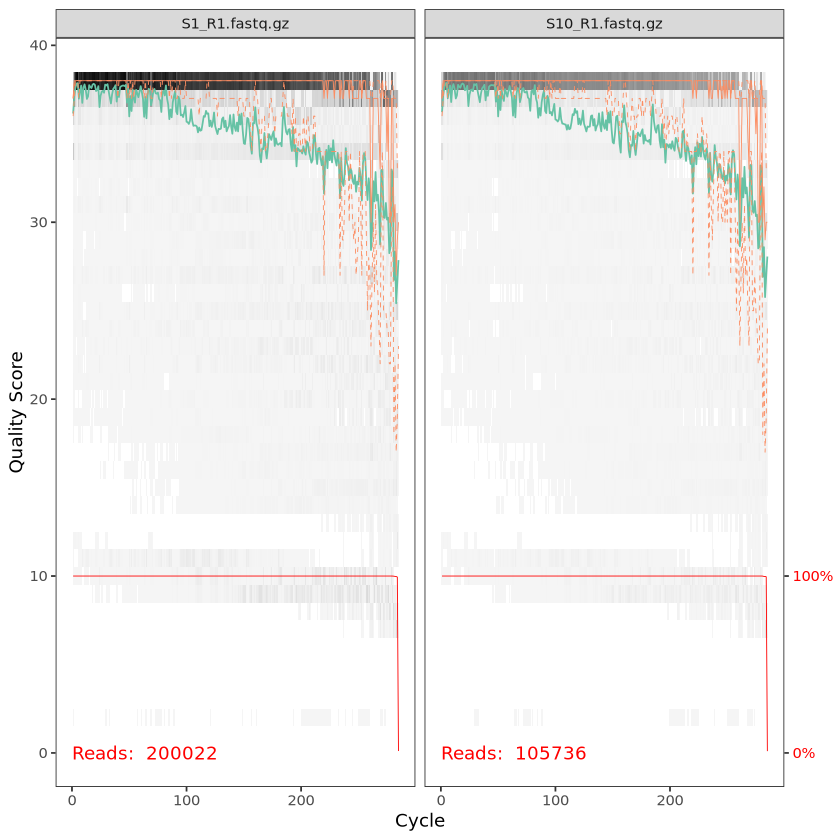

    reads.in reads.out
S1    200022    122987
S10   105736     65309
S11    67889     38321
S12    75568     44333
S13    80394     42797
S15    56804     32801
S16    80969     47037
S17    37044     21649
S18   127500     68395
S19   112434     60617
S2    196500    121493
S20    70685     35753
S21   112418     51626
S22    90087     45652
S3    200255    118301
S4     95373     56285
S5     80955     46411
S6     84996     46539
S7     56675     34554
S8     48248     29223
S9     89408     54771
Retained after quality filtering: 57.2 % | samples: 21 / 21 


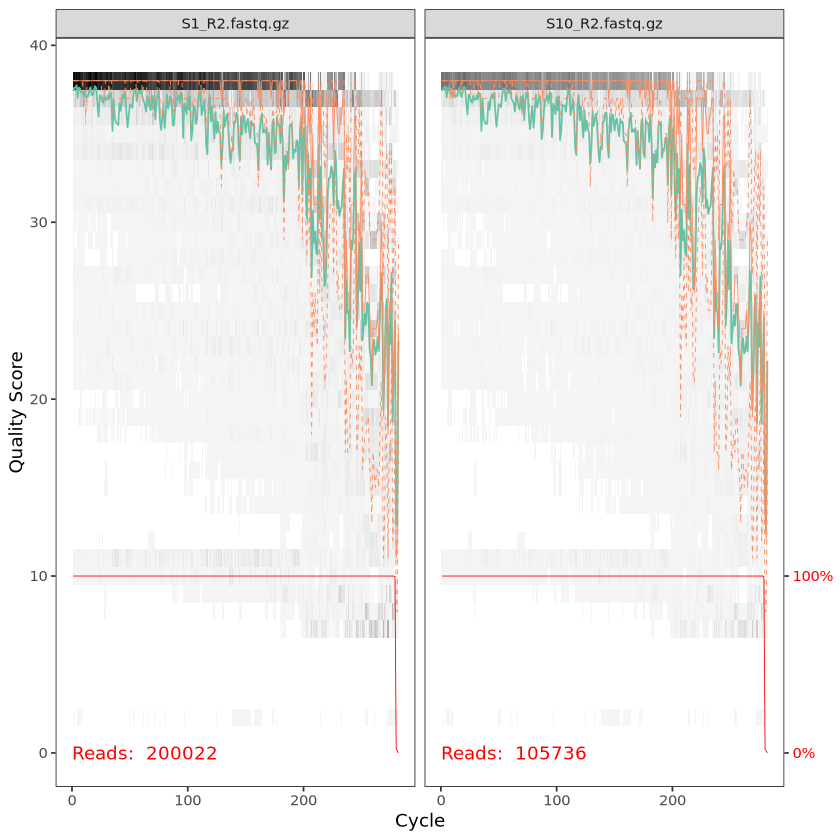

In [6]:
print(dada2::plotQualityProfile(unname(trim_f[preview_ids])))
print(dada2::plotQualityProfile(unname(trim_r[preview_ids])))
filtered_dir <- file.path(outdir, "filtered")
dir.create(filtered_dir, recursive=TRUE, showWarnings=FALSE)
filt_f <- setNames(file.path(filtered_dir, paste0(sample_ids, "_R1.fastq.gz")), sample_ids)
filt_r <- setNames(file.path(filtered_dir, paste0(sample_ids, "_R2.fastq.gz")), sample_ids)
filter_stats <- dada2::filterAndTrim(unname(trim_f), unname(filt_f),
  unname(trim_r), unname(filt_r), truncLen=trunc_len,
  maxN=0, maxEE=max_ee, truncQ=2, minLen=min_len, rm.phix=TRUE,
  compress=TRUE, multithread=threads, verbose=TRUE)
rownames(filter_stats) <- sample_ids
keep <- filter_stats[, "reads.out"] >= min_reads
kept_ids <- sample_ids[keep]
if (!length(kept_ids)) stop("No samples passed DADA2 filter")
saveRDS(filter_stats, file.path(outdir, "filter_stats.rds"))
write_matrix(filter_stats, "filter_stats.tsv")
print(filter_stats)
cat("Retained after quality filtering:",
    round(100 * sum(filter_stats[,"reads.out"]) / sum(filter_stats[,"reads.in"]), 1),
    "% | samples:", length(kept_ids), "/", length(sample_ids), "\n")

## 7. Обучение моделей ошибок DADA2 для R1 и R2

Предупреждения ggplot `scale_y_log10()` при `plotErrors()` возможны из-за нулевых частот; это не означает сбой `learnErrors()`.

111719141 total bases in 393585 reads from 7 samples will be used for learning the error rates.
109707145 total bases in 393585 reads from 7 samples will be used for learning the error rates.


Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message:
“Removed 164 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 164 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 164 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 164 rows containing missing values or values outside the scale range (`geom_line()`).”


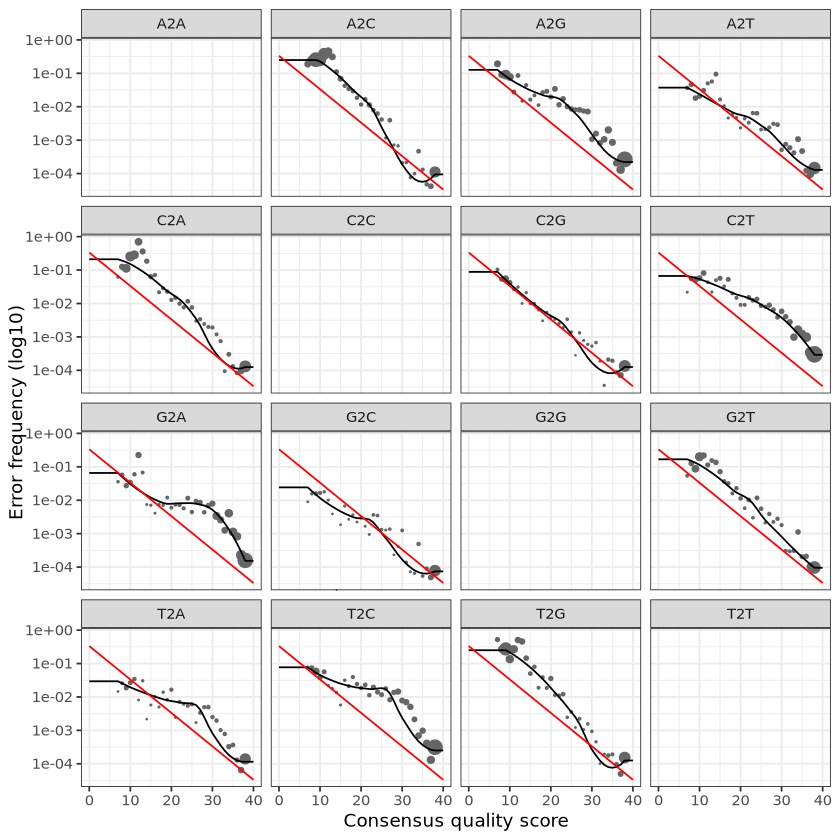

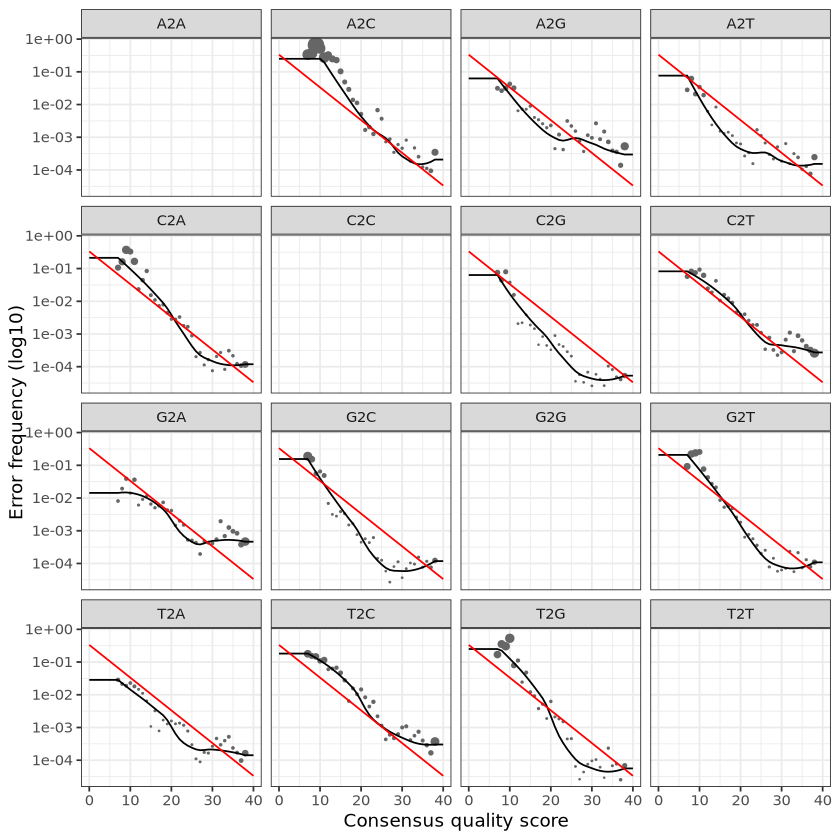

In [7]:
err_f <- dada2::learnErrors(unname(filt_f[kept_ids]), multithread=threads)
err_r <- dada2::learnErrors(unname(filt_r[kept_ids]), multithread=threads)
saveRDS(list(err_f=err_f, err_r=err_r), file.path(outdir, "error_models.rds"))
print(dada2::plotErrors(err_f, nominalQ=TRUE))
print(dada2::plotErrors(err_r, nominalQ=TRUE))

## 8. Дерепликация и денойзинг DADA2

`derepFastq()` группирует идентичные прочтения, `dada()` определяет реальные варианты с использованием моделей ошибок. R1/R2 обрабатываются отдельно. Результаты этой ячейки не являются итоговой таблицей ASV до объединения пар и удаления химер.

In [8]:
derep_f <- dada2::derepFastq(unname(filt_f[kept_ids]), verbose=FALSE)
derep_r <- dada2::derepFastq(unname(filt_r[kept_ids]), verbose=FALSE)
names(derep_f) <- names(derep_r) <- kept_ids
dada_f <- dada2::dada(derep_f, err=err_f, pool=pooling, multithread=threads)
dada_r <- dada2::dada(derep_r, err=err_r, pool=pooling, multithread=threads)
stopifnot(identical(names(dada_f), kept_ids), identical(names(dada_r), kept_ids))
saveRDS(list(dada_f=dada_f, dada_r=dada_r,
             derep_f=derep_f, derep_r=derep_r),
        file.path(outdir, "denoised_pairs.rds"))
cat("Denoised samples:", length(dada_f), "\n")

Sample 1 - 122987 reads in 6606 unique sequences.
Sample 2 - 65309 reads in 3142 unique sequences.
Sample 3 - 38321 reads in 2138 unique sequences.
Sample 4 - 44333 reads in 2463 unique sequences.
Sample 5 - 42797 reads in 5242 unique sequences.
Sample 6 - 32801 reads in 3255 unique sequences.
Sample 7 - 47037 reads in 5340 unique sequences.
Sample 8 - 21649 reads in 2650 unique sequences.
Sample 9 - 68395 reads in 4997 unique sequences.
Sample 10 - 60617 reads in 4946 unique sequences.
Sample 11 - 121493 reads in 6528 unique sequences.
Sample 12 - 35753 reads in 4070 unique sequences.
Sample 13 - 51626 reads in 11216 unique sequences.
Sample 14 - 45652 reads in 3194 unique sequences.
Sample 15 - 118301 reads in 5831 unique sequences.
Sample 16 - 56285 reads in 3084 unique sequences.
Sample 17 - 46411 reads in 3044 unique sequences.
Sample 18 - 46539 reads in 4927 unique sequences.
Sample 19 - 34554 reads in 2316 unique sequences.
Sample 20 - 29223 reads in 1781 unique sequences.
Sampl

## 9. Объединение пар, таблица ASV и удаление химер

`mergePairs()` требует перекрытие R1/R2 не менее 12 нуклеотидов; для ITS длинные ампликоны могут **не перекрываться**, и это нельзя исправлять искусственным конкатенированием без отдельного решения. При низкой сохранности объединения остановись для диагностики. `makeSequenceTable()` и `removeBimeraDenovo()` выполняются здесь, в правильном порядке.

In [9]:
mergers <- dada2::mergePairs(dada_f, derep_f, dada_r, derep_r,
                            minOverlap=min_overlap, maxMismatch=0, verbose=TRUE)
merge_counts <- vapply(mergers, function(z) sum(dada2::getUniques(z)), numeric(1))
merge_in <- pmin(vapply(dada_f, function(z) sum(dada2::getUniques(z)), numeric(1)),
                 vapply(dada_r, function(z) sum(dada2::getUniques(z)), numeric(1)))
merge_rate <- merge_counts / pmax(merge_in, 1)
merge_qc <- data.frame(sample_id=names(merge_counts), pairs_considered=merge_in,
                       merged=merge_counts, merged_pct=round(100*merge_rate, 2))
write_rows(merge_qc, "merge_success.tsv")
print(merge_qc, row.names=FALSE)
if (any(merge_rate < 0.5)) warning("Some samples have <50% merge success. Check ITS amplicon length/primers/quality")

seqtab_before_chimera <- dada2::makeSequenceTable(mergers)
seqtab_nochim <- dada2::removeBimeraDenovo(
  seqtab_before_chimera, method="consensus", multithread=threads)
if (!ncol(seqtab_nochim) || sum(seqtab_nochim)==0) stop("No non-chimeric ASVs remain")
saveRDS(seqtab_before_chimera, file.path(outdir, "seqtab_before_chimera.rds"))
saveRDS(seqtab_nochim, file.path(outdir, "seqtab_nochim.rds"))
cat("ASVs before chimera removal:", ncol(seqtab_before_chimera),
    "| after:", ncol(seqtab_nochim),
    "| non-chimeric reads:", sum(seqtab_nochim), "\n")

121982 paired-reads (in 197 unique pairings) successfully merged out of 122565 (in 291 pairings) input.

65090 paired-reads (in 105 unique pairings) successfully merged out of 65181 (in 140 pairings) input.

38069 paired-reads (in 112 unique pairings) successfully merged out of 38171 (in 151 pairings) input.

44073 paired-reads (in 100 unique pairings) successfully merged out of 44177 (in 137 pairings) input.

40735 paired-reads (in 635 unique pairings) successfully merged out of 41916 (in 931 pairings) input.

32488 paired-reads (in 197 unique pairings) successfully merged out of 32724 (in 231 pairings) input.

45420 paired-reads (in 591 unique pairings) successfully merged out of 46439 (in 815 pairings) input.

Duplicate sequences in merged output.

20950 paired-reads (in 306 unique pairings) successfully merged out of 21292 (in 431 pairings) input.

67721 paired-reads (in 206 unique pairings) successfully merged out of 68358 (in 238 pairings) input.

59484 paired-reads (in 436 uniqu

 sample_id pairs_considered merged merged_pct
        S1           122711 121982      99.41
       S10            65221  65090      99.80
       S11            38219  38069      99.61
       S12            44235  44073      99.63
       S13            42293  40735      96.32
       S15            32751  32488      99.20
       S16            46703  45420      97.25
       S17            21438  20950      97.72
       S18            68376  67721      99.04
       S19            60481  59484      98.35
        S2           121235 120835      99.67
       S20            35509  34283      96.55
       S21            49883  44420      89.05
       S22            45600  45340      99.43
        S3           118059 117362      99.41
        S4            56199  56099      99.82
        S5            46354  46220      99.71
        S6            46313  46079      99.49
        S7            34513  34418      99.72
        S8            29203  29146      99.80
        S9            54758  54734

Duplicate sequences detected and merged.

Duplicate sequences detected and merged.



ASVs before chimera removal: 3379 | after: 2507 | non-chimeric reads: 1155686 


## 10. Таксономия: SILVA 144, включая поиск видовых совпадений

Классификация `assignTaxonomy()` по 7 уровням и затем `addSpecies()` по **видовому** файлу SILVA. Отсутствие точного совпадения даёт `NA`; совпадение участка 16S не всегда позволяет отличить близкие виды.

In [10]:
sequences <- colnames(seqtab_nochim)
tax_by_seq <- dada2::assignTaxonomy(sequences, taxonomy_ref,
  minBoot=min_boot, taxLevels=tax_levels, tryRC=try_rc,
  multithread=threads)
tax_by_seq <- dada2::addSpecies(tax_by_seq, species_ref)
asv_ids <- paste0("ASV", sprintf("%06d", seq_along(sequences)))
seq_map <- setNames(sequences, asv_ids)
seqtab <- seqtab_nochim
colnames(seqtab) <- asv_ids
tax <- tax_by_seq
rownames(tax) <- asv_ids
stopifnot(identical(colnames(seqtab), rownames(tax)))
saveRDS(tax_by_seq, file.path(outdir, "taxonomy_by_sequence.rds"))
saveRDS(tax, file.path(outdir, "taxonomy_all_asvs.rds"))
saveRDS(seq_map, file.path(outdir, "asv_sequence_map.rds"))
write_matrix(tax_by_seq, "taxonomy_by_sequence.tsv")
write_matrix(tax, "taxonomy_all_asvs.tsv")
print(head(tax))
cat("Taxonomy assigned to:", nrow(tax), "ASVs\n")

          Domain     Kingdom                 Phylum          
ASV000001 "Bacteria" "Pseudomonadati"        "Pseudomonadota"
ASV000002 "Bacteria" "Pseudomonadati"        "Pseudomonadota"
ASV000003 "Bacteria" "Pseudomonadati"        "Pseudomonadota"
ASV000004 "Bacteria" "Bacillati"             "Bacillota"     
ASV000005 "Bacteria" "Pseudomonadati"        "Pseudomonadota"
ASV000006 "Bacteria" "Pseudomonadati--other" "Bacteroidota"  
          Class                 Order                     Family               
ASV000001 "Alphaproteobacteria" "Sphingomonadales"        "Sphingomonadaceae"  
ASV000002 "Alphaproteobacteria" "Hyphomicrobiales--other" "Methylobacteriaceae"
ASV000003 "Gammaproteobacteria" "Burkholderiales"         "Comamonadaceae"     
ASV000004 "Bacilli"             "Lactobacillales"         "Enterococcaceae"    
ASV000005 "Alphaproteobacteria" "Hyphomicrobiales--other" "Methylobacteriaceae"
ASV000006 "Bacteroidia"         "Bacteroidales"           "Bacteroidaceae"     
      

## 11. Нецелевые 16S ASV, `phyloseq` и сохранение таблиц

Удаляем ASV с `Chloroplast` или `Mitochondria` на любом уровне; все классификации до исключения сохранены. Отрицательных контролей в опубликованных метаданных нет — **`decontam` не выполняется**.

In [14]:
stopifnot(identical(colnames(seqtab), rownames(tax)))

full_mat <- seqtab
full_tax <- tax

# Исключение органелл и ASV вне домена Bacteria
organelles <- apply(tax, 1, function(z)
  any(grepl("Chloroplast|Mitochondria", z, ignore.case=TRUE),
      na.rm=TRUE))

domain <- trimws(as.character(tax[, "Domain"]))
non_bacteria <- is.na(domain) | domain == "" |
                tolower(domain) != "bacteria"

excluded <- organelles | non_bacteria

cat("Organelles:", sum(organelles), "\n")
cat("Non-bacterial/unassigned:", sum(non_bacteria), "\n")
cat("Total excluded:", sum(excluded), "\n")

# Таблица причин исключения
audit <- data.frame(
  ASV = rownames(tax),
  Domain = domain,
  excluded = excluded,
  reason = ifelse(organelles, "Organelle",
           ifelse(non_bacteria, "Non-bacterial/unassigned", "Keep"))
)

write_rows(audit, "taxonomy_filter_audit.tsv")

write_matrix(full_mat, "asv_counts_all.tsv")
write_matrix(full_tax, "taxonomy_all_asvs.tsv")
saveRDS(full_mat, file.path(outdir, "asv_counts_all.rds"))
saveRDS(full_tax, file.path(outdir, "taxonomy_all_asvs.rds"))

if (any(excluded)) {
  write_matrix(tax[excluded, , drop=FALSE],
               "excluded_asv_taxonomy.tsv")
}

# Фильтрация
mat <- seqtab[, !excluded, drop=FALSE]
tax_target <- tax[!excluded, , drop=FALSE]

mat <- mat[rowSums(mat) > 0, , drop=FALSE]
if (nrow(mat) == 0 || ncol(mat) == 0)
  stop("No bacterial ASVs remain")

tax_target <- tax_target[colnames(mat), , drop=FALSE]
stopifnot(identical(colnames(mat), rownames(tax_target)))

meta_for_ps <- meta[
  match(rownames(mat), meta$sample_id), , drop=FALSE
]
if (anyNA(meta_for_ps$sample_id))
  stop("Missing metadata for some samples")

rownames(meta_for_ps) <- meta_for_ps$sample_id

ps <- phyloseq::phyloseq(
  phyloseq::otu_table(mat, taxa_are_rows=FALSE),
  phyloseq::tax_table(as.matrix(tax_target)),
  phyloseq::sample_data(meta_for_ps)
)

write_matrix(mat, "asv_counts_target.tsv")
write_matrix(tax_target, "taxonomy_target.tsv")
write_rows(meta_for_ps, "metadata_target.tsv")

saveRDS(mat, file.path(outdir, "asv_counts_target.rds"))
saveRDS(tax_target, file.path(outdir, "taxonomy_target.rds"))
saveRDS(ps, file.path(outdir, "phyloseq.rds"))

fasta <- Biostrings::DNAStringSet(unname(seq_map))
names(fasta) <- names(seq_map)

Biostrings::writeXStringSet(
  fasta, file.path(outdir, "asv_sequences_all.fasta")
)

cat("Final:", nrow(mat), "samples x",
    ncol(mat), "bacterial ASVs\n")

Organelles: 28 
Non-bacterial/unassigned: 10 
Total excluded: 38 
Final: 21 samples x 2469 bacterial ASVs


## 12. Прослеживание числа прочтений (read tracking)

Считаем потери на каждом этапе: исходные FASTQ → удаление праймеров → DADA2 → объединение → нехимерные последовательности → целевая группа. Это **разные единицы по этапам**, но они согласованно представлены как количество пар/объединённых прочтений.

In [15]:
get_n <- function(z) sum(dada2::getUniques(z))
track <- data.frame(sample_id=sample_ids,
  raw_pairs=cut_qc$raw_pairs,
  after_cutadapt=cut_qc$trimmed_pairs,
  filtered=as.numeric(filter_stats[,"reads.out"]),
  denoisedF=NA_real_, denoisedR=NA_real_, merged=NA_real_,
  nonchim=NA_real_, target=NA_real_, stringsAsFactors=FALSE)
rownames(track) <- track$sample_id
track[kept_ids,"denoisedF"] <- vapply(dada_f, get_n, numeric(1))
track[kept_ids,"denoisedR"] <- vapply(dada_r, get_n, numeric(1))
track[names(merge_counts),"merged"] <- as.numeric(merge_counts)
track[rownames(seqtab_nochim),"nonchim"] <- rowSums(seqtab_nochim)
track[rownames(mat),"target"] <- rowSums(mat)
track$retained_raw_pct <- round(100*track$target/track$raw_pairs, 2)
track$retained_trimmed_pct <- round(100*track$target/track$after_cutadapt, 2)
write_rows(track, "read_tracking.tsv")
saveRDS(track, file.path(outdir, "read_tracking.rds"))
print(track)

    sample_id raw_pairs after_cutadapt filtered denoisedF denoisedR merged
S1         S1    201658         200022   122987    122711    122767 121982
S10       S10    106497         105736    65309     65229     65221  65090
S11       S11     68417          67889    38321     38219     38222  38069
S12       S12     76122          75568    44333     44235     44246  44073
S13       S13     81396          80394    42797     42306     42293  40735
S15       S15     57345          56804    32801     32773     32751  32488
S16       S16     81929          80969    47037     46719     46703  45420
S17       S17     37564          37044    21649     21461     21438  20950
S18       S18    129030         127500    68395     68376     68376  67721
S19       S19    113780         112434    60617     60481     60516  59484
S2         S2    198183         196500   121493    121359    121235 120835
S20       S20     71784          70685    35753     35520     35509  34283
S21       S21    115185  

## 13. Альфа-разнообразие

`Observed`, Shannon, Simpson, Pielou рассчитываются на абсолютных счётчиках ASV. **Observed зависит от глубины секвенирования**, поэтому сравнивать Flight/Ground только по этому графику нельзя. Сохраняем значения и опубликованные метаданные.

    sample_id  reads Observed   Shannon    Simpson     Pielou site_type
S1         S1 121259      153 0.4288117 0.11525354 0.08524342    Flight
S10       S10  65034       95 0.2824888 0.07310035 0.06203260    Ground
S11       S11  38015       98 0.3692802 0.09861910 0.08054151    Ground
S12       S12  43998       84 0.2448454 0.06456300 0.05525966    Ground
S13       S13  40010      511 1.6596694 0.38589472 0.26612750    Flight
S15       S15  32322      181 0.9785131 0.24182554 0.18822999    Flight
S16       S16  44712      481 1.5552745 0.36294960 0.25183095    Ground
S17       S17  20784      265 1.1322983 0.27689954 0.20293067    Flight
S18       S18  66808      188 1.5821695 0.40685376 0.30214591    Ground
S19       S19  58784      381 1.5276623 0.35935129 0.25706106    Flight
S2         S2 120413      108 0.3107343 0.08714860 0.06636600    Ground
S20       S20  33602      460 2.0562874 0.47532549 0.33537945    Ground
S21       S21  40841      820 3.7140944 0.80522888 0.55357369   

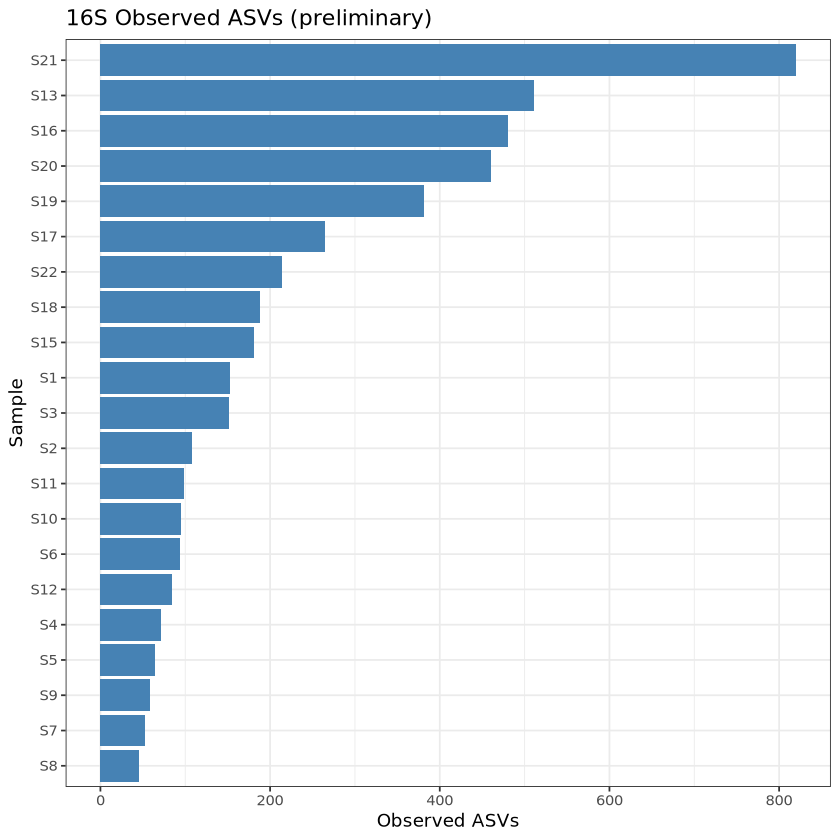

In [16]:
rel <- sweep(mat, 1, rowSums(mat), "/")
alpha <- data.frame(sample_id=rownames(mat), reads=rowSums(mat),
  Observed=rowSums(mat>0), Shannon=vegan::diversity(mat, "shannon"),
  Simpson=vegan::diversity(mat, "simpson"))
alpha$Pielou <- ifelse(alpha$Observed>1,
  alpha$Shannon/log(alpha$Observed), NA_real_)
for (field in intersect(c("site_type", "sampling_date", "altitude_min_m",
                          "altitude_max_m", "air_volume_m3", "dna_yield_ng_m3"), names(meta_for_ps)))
  alpha[[field]] <- meta_for_ps[match(alpha$sample_id, meta_for_ps$sample_id), field]
write_rows(alpha, "alpha_diversity.tsv")
saveRDS(alpha, file.path(outdir, "alpha_diversity.rds"))
write_matrix(rel, "asv_relative_abundance.tsv")
print(alpha)
p_alpha <- ggplot2::ggplot(alpha, ggplot2::aes(x=reorder(sample_id, Observed), y=Observed)) +
  ggplot2::geom_col(fill="steelblue") + ggplot2::coord_flip() +
  ggplot2::theme_bw() + ggplot2::labs(title=paste(marker, "Observed ASVs (preliminary)"),
                                    x="Sample", y="Observed ASVs")
print(p_alpha)
ggplot2::ggsave(file.path(outdir,"observed_ASVs.png"), p_alpha,
                width=7, height=6, dpi=160)

## 14. Кривые накопления ASV (rarefaction)

Проверяем достаточность глубины секвенирования по выборочным кривым, **без изменения основной ASV-таблицы**. Это диагностический график, а не автоматическая нормализация. При значительных различиях глубины дальнейшее сравнение Observed следует стандартизировать.

In [17]:
if (nrow(mat)>=2 && ncol(mat)>=2) {
  png(file.path(outdir,"rarefaction_curves.png"), width=1200, height=750, res=140)
  vegan::rarecurve(mat, step=max(1L, floor(min(rowSums(mat))/25)),
                   sample=min(rowSums(mat)), label=FALSE,
                   xlab="Sequenced reads", ylab="Observed ASVs",
                   main=paste(marker, "Rarefaction curves (diagnostic)"))
  dev.off()
  cat("Rarefaction curves saved. Min depth:", min(rowSums(mat)), "\n")
}

Rarefaction curves saved. Min depth: 20784 


## 15. Относительная численность родов

Объединяем ASV по `Genus`. Неопределённые рода обозначаем `Unclassified`, менее распространённые — `Other`. Все значения сохраняются в TSV, а не только показанные на графике.

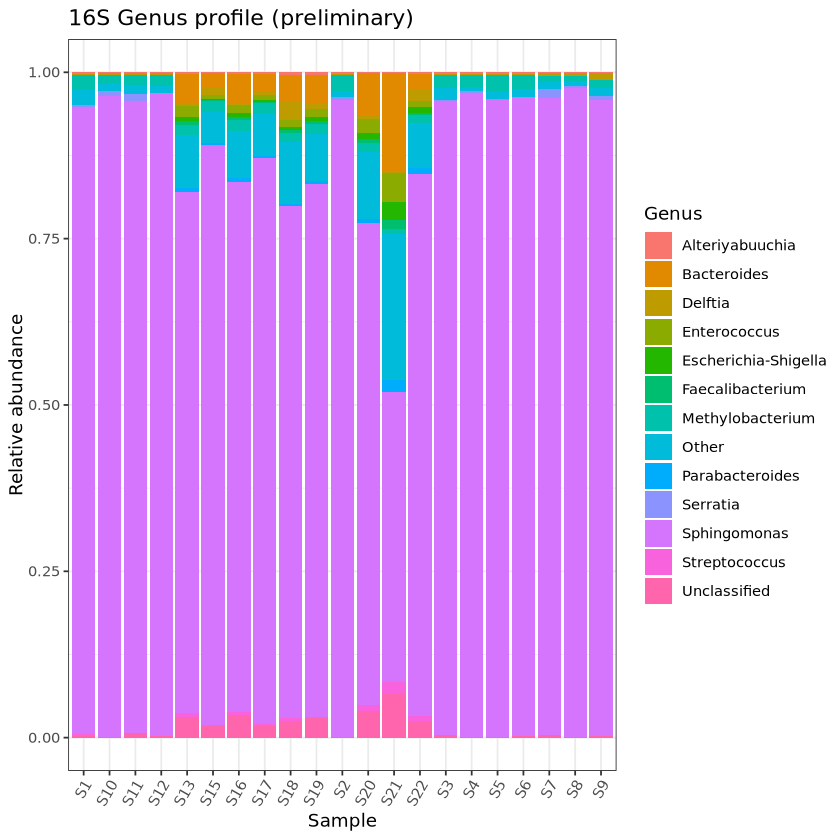

In [18]:
if (!"Genus" %in% colnames(tax_target)) stop("No Genus rank in taxonomy")
genus <- as.character(tax_target[colnames(rel), "Genus"])
genus[is.na(genus) | !nzchar(genus)] <- "Unclassified"
genus_rel <- t(rowsum(t(rel), group=genus, reorder=TRUE))
write_matrix(genus_rel, "relative_genus.tsv")
leaders <- head(names(sort(colMeans(genus_rel), decreasing=TRUE)), 12L)
plot_tab <- genus_rel[, leaders, drop=FALSE]
if (ncol(plot_tab)<ncol(genus_rel)) plot_tab <- cbind(plot_tab, Other=pmax(0, 1-rowSums(plot_tab)))
plot_df <- as.data.frame(as.table(plot_tab), stringsAsFactors=FALSE)
names(plot_df) <- c("Sample", "Genus", "Relative_abundance")
plot_df$Sample <- factor(plot_df$Sample, levels=rownames(genus_rel))
p_genus <- ggplot2::ggplot(plot_df, ggplot2::aes(Sample, Relative_abundance, fill=Genus)) +
  ggplot2::geom_col() + ggplot2::theme_bw() +
  ggplot2::theme(axis.text.x=ggplot2::element_text(angle=60, hjust=1)) +
  ggplot2::labs(title=paste(marker, "Genus profile (preliminary)"),
                x="Sample", y="Relative abundance")
print(p_genus)
ggplot2::ggsave(file.path(outdir, "genus_profiles.png"), p_genus,
                width=12, height=6, dpi=160)

## 16. Бета-разнообразие и PCoA

Bray–Curtis — на относительных численностях ASV; Jaccard — на присутствии/отсутствии. PCoA — обзорный график. Если присутствуют группы Flight/Ground и есть повторы, отдельно выполняем **PERMANOVA** и **анализ дисперсии групп**; PERMANOVA может отражать различия дисперсий, а не центров групп.

Permutation test for adonis under reduced model
Permutation: free
Number of permutations: 999

vegan::adonis2(formula = bray ~ site_type, data = perm_data, permutations = 999)
         Df SumOfSqs      R2      F Pr(>F)
Model     1  0.01572 0.03618 0.7133  0.522
Residual 19  0.41871 0.96382              
Total    20  0.43443 1.00000              
Analysis of Variance Table

Response: Distances
          Df   Sum Sq   Mean Sq F value Pr(>F)
Groups     1 0.008044 0.0080439  0.5103 0.4837
Residuals 19 0.299528 0.0157646               


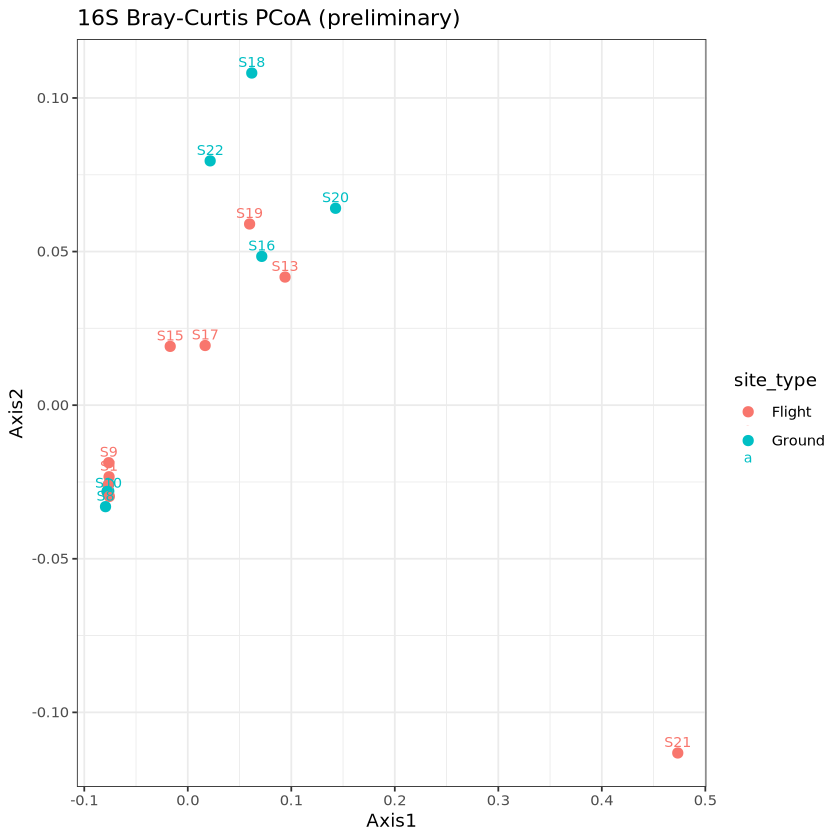

In [19]:
if (nrow(mat)>=3L && ncol(mat)>=2L) {
  bray <- vegan::vegdist(rel, method="bray")
  jaccard <- vegan::vegdist(mat>0, method="jaccard", binary=TRUE)
  write_matrix(as.matrix(bray), "bray_curtis.tsv")
  write_matrix(as.matrix(jaccard), "jaccard.tsv")
  pcoa <- stats::cmdscale(bray, k=2, eig=TRUE, add=TRUE)
  pcoa_df <- data.frame(sample_id=rownames(pcoa$points),
                        Axis1=pcoa$points[,1], Axis2=pcoa$points[,2])
  for (field in intersect(c("site_type","sampling_date"),names(meta_for_ps)))
    pcoa_df[[field]] <- meta_for_ps[match(pcoa_df$sample_id,meta_for_ps$sample_id),field]
  write_rows(pcoa_df, "pcoa_bray.tsv")
  p_pcoa <- if ("site_type" %in% names(pcoa_df))
    ggplot2::ggplot(pcoa_df, ggplot2::aes(Axis1, Axis2, color=site_type, label=sample_id))
  else ggplot2::ggplot(pcoa_df, ggplot2::aes(Axis1, Axis2, label=sample_id))
  p_pcoa <- p_pcoa + ggplot2::geom_point(size=2.5) +
    ggplot2::geom_text(vjust=-0.6, check_overlap=TRUE, size=3) +
    ggplot2::theme_bw() +
    ggplot2::labs(title=paste(marker,"Bray-Curtis PCoA (preliminary)"))
  print(p_pcoa)
  ggplot2::ggsave(file.path(outdir,"pcoa_bray.png"),p_pcoa,width=7,height=5,dpi=160)

  if ("site_type" %in% names(pcoa_df)) {
    group <- factor(meta_for_ps[match(rownames(mat),meta_for_ps$sample_id),"site_type"])
    if (all(!is.na(group)) && length(levels(group))==2 && all(table(group)>=2)) {
      perm_data <- data.frame(site_type=group, row.names=rownames(mat))
      perm <- vegan::adonis2(bray ~ site_type, data=perm_data, permutations=999)
      disp <- vegan::betadisper(bray, group)
      disp_test <- stats::anova(disp)
      writeLines(capture.output(perm),file.path(outdir,"permanova_flight_ground.txt"))
      writeLines(capture.output(disp_test),file.path(outdir,"betadisper_flight_ground.txt"))
      print(perm); print(disp_test)
    }
  }
} else cat("Too few ASVs or samples for beta diversity\n")

## 17. Связь с погодой и экстремальными событиями (если добавлены данные)

В исходных метаданных погода обозначена как `NA`: **не выдумываем** температуру, ветер, осадки или даты экстремальных событий. Если в `metadata/samples_pnas.tsv` добавлены настоящие поля `temp_c`, `rh_pct`, `wind_ms`, `precip_mm`, `pressure_hpa`, `pm25`, `pm10`, выполняем **разведочный** коэффициент Спирмена с Shannon. Если есть колонка `extreme_event` со значениями `TRUE/FALSE` (или 1/0), считаем распределение событий и описательную разницу. Нужны проверки сезонности, партия/высота, временные лаги и достоверность измерений для дипломных выводов.

In [20]:
weather_columns <- c("temp_c","rh_pct","wind_ms","precip_mm",
                     "pressure_hpa","pm25","pm10")
weather_rows <- list()
for (field in intersect(weather_columns, names(meta_for_ps))) {
  x <- suppressWarnings(as.numeric(meta_for_ps[alpha$sample_id, field]))
  y <- alpha$Shannon
  ok <- is.finite(x) & is.finite(y)
  if (sum(ok)>=8 && length(unique(x[ok]))>=3) {
    test <- suppressWarnings(stats::cor.test(x[ok],y[ok],method="spearman",exact=FALSE))
    weather_rows[[field]] <- data.frame(variable=field, n=sum(ok),
      rho=unname(test$estimate), p_value=test$p.value)
  }
}
if (length(weather_rows)) {
  weather_associations <- do.call(rbind,weather_rows)
  weather_associations$p_BH <- p.adjust(weather_associations$p_value,"BH")
  write_rows(weather_associations,"weather_shannon_spearman.tsv")
  print(weather_associations)
} else cat("Weather measurements not available or insufficient: no weather correlations.\n")
if ("extreme_event" %in% names(meta_for_ps)) {
  event <- as.character(meta_for_ps[alpha$sample_id,"extreme_event"])
  event[event %in% c("1","TRUE","true","T")] <- "TRUE"
  event[event %in% c("0","FALSE","false","F")] <- "FALSE"
  valid <- !is.na(event) & event %in% c("TRUE","FALSE")
  if (sum(valid)>0) {
    event_summary <- aggregate(alpha$Shannon[valid], list(extreme_event=event[valid]),
                               function(z) c(n=length(z), mean=mean(z),median=median(z)))
    print(event_summary)
    cat("Event categories: exploratory; not proof of causal weather effects.\n")
  }
}

Weather measurements not available or insufficient: no weather correlations.


## 18. Сводка и воспроизводимость

Сохраняются сведения о версии R, библиотек и программах. Весь анализ выполнен заново из исходных FASTQ; список результатов можно посмотреть в JupyterLab в папке `results/{marker}`. Для научной интерпретации проверь отрицательные контроли и реальные метеоданные.

In [21]:
writeLines(capture.output(sessionInfo()), file.path(outdir,"sessionInfo.txt"))
versions <- c(cutadapt=system2(Sys.which("cutadapt"),"--version",stdout=TRUE),
              fastqc=if (run_fastqc) paste(system2(Sys.which("fastqc"),"--version",stdout=TRUE),collapse=" ") else "not run",
              multiqc=if (run_fastqc) paste(system2(Sys.which("multiqc"),"--version",stdout=TRUE),collapse=" ") else "not run")
writeLines(paste(names(versions), versions, sep=" = "),file.path(outdir,"tool_versions.txt"))
cat("Finished:",marker,"\nSamples:",nrow(mat),"\nTarget ASVs:",ncol(mat),
    "\nFinal reads:",sum(mat),"\nOutput:",outdir,
    "\nNegative controls: not provided/verified; decontam not run.",
    "\nWeather: only analyzed if actual metadata supplied.",
    "\nSave the notebook with Ctrl+S.\n")

Warning message:
“‘timedatectl’ indicates the non-existent timezone name ‘n/a’”
Warning message:
“Your system is mis-configured: ‘/etc/localtime’ is not a symlink”
Warning message:
“‘/etc/localtime’ is not identical to any known timezone file”


Finished: 16S 
Samples: 21 
Target ASVs: 2469 
Final reads: 1154733 
Output: /home/panishevasa/airlab/pipeline/results/16S 
Negative controls: not provided/verified; decontam not run. 
Weather: only analyzed if actual metadata supplied. 
Save the notebook with Ctrl+S.
